# Continuous Bag of Words (CBOW)

In this notebook we train **word embeddings** from scratch: each word of the vocabulary gets a vector of 100 numbers, and we want words used in similar contexts (e.g. *he* / *she*, *cold* / *winter*) to end up with similar vectors.

The idea of CBOW (Mikolov et al., 2013, *word2vec*): **predict a word from the words around it**.

```
the  cat  [ ? ]  on  the        context  ->  center word
 i-2  i-1   i    i+1 i+2        {the, cat, on, the}  ->  "sat"
```

To succeed at this task, the network must learn a useful representation of each word: this representation is the embedding.

In [1]:
import random
from collections import Counter, defaultdict
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset


## 1. The data: `text8`

`text8` is the first $10^8$ characters of an English Wikipedia dump, already cleaned: lowercase, no punctuation, numbers spelled out (`"1984"` → `"one nine eight four"`).
We download it once and split it into a list of words.

In [2]:
if not Path("text8.zip").exists():
    urlretrieve("http://mattmahoney.net/dc/text8.zip", "text8.zip")
words = ZipFile("text8.zip").read("text8").decode().split()

How many words (tokens) do we have, and how many *distinct* words?

In [3]:
len(words)

17005207

In [4]:
len(set(words))

253854

The most common words are (unsurprisingly) short function words, and number words (because digits were spelled out).
Word frequencies follow **Zipf's law**: a few words are extremely frequent, and most words are very rare.

In [5]:
c = Counter(words)
print(c.most_common(10))

[('the', 1061396), ('of', 593677), ('and', 416629), ('one', 411764), ('in', 372201), ('a', 325873), ('to', 316376), ('zero', 264975), ('nine', 250430), ('two', 192644)]


## 2. The vocabulary

A neural network works with numbers, not strings. We build two lookup tables:
- `itos` (*integer to string*): a list, `itos[i]` is the $i$-th word;
- `stoi` (*string to integer*): a dict, `stoi[word]` is its index.

With ~250k distinct words, the model would be too big (the input and output layers both have one neuron per word). Since most words are rare anyway, we keep only the **10 000 most frequent words**, and every other word is mapped to a special token `UNK` (*unknown*), with index 10000.

In [6]:
itos: list[str] = []
# for word in set(words):  # <-- would be great... but we don't have data centers at disposal
for word, word_count in c.most_common(10000):
    itos.append(word)
itos.append("UNK")

In [7]:
stoi: dict[str, int] = {}
for i in range(len(itos)):
    stoi[itos[i]] = i
for word in words:
    if word not in stoi:
        stoi[word] = 10000
stoi["the"], itos[0]

(0, 'the')

Our vocabulary therefore has 10 001 tokens.

In [8]:
vocab_size = len(itos)

## 3. The dataset

Each training example is built from a position $i$ in the text:
- input `x`: the indices of the 4 context words at positions $i-2, i-1, i+1, i+2$;
- target `y`: the index of the center word at position $i$.

Instead of going through every position, `__getitem__` picks a **random** position each time (the index `k` is ignored). We also set the length of the dataset to `len(words) // 500` (≈ 34 000 examples), so that one "epoch" is short and we can monitor the training often.

In [9]:
class WordDataset(Dataset):
    def __init__(self):
        super().__init__()
        print("Object created")

    def __len__(self):
        return len(words) // 500
    
    def __getitem__(self, k):
        # we want to return x, y
        i = random.randint(2, len(words) - 3)
        # x will be the integers that represent the words
        # at positions i-2, i-1, i+1, i+2
        x = torch.tensor(
            [stoi[words[i-2]], stoi[words[i-1]], stoi[words[i+1]], stoi[words[i+2]]]
        )
        y = stoi[words[i]]
        return x, y
    
dataset = WordDataset()
dataset[5]

Object created


(tensor([ 3,  9, 15, 32]), 3)

## 4. The model

The architecture is very simple: two linear layers, no non-linearity.

1. **Encoding the input.** The 4 context words are encoded as a single *multi-hot* vector of size `vocab_size`: a 1 at the index of each context word, 0 elsewhere. The order of the words is lost: this is why it's called a *bag* of words.
2. **Encoder** (`vocab_size` → 100, no bias). Multiplying a multi-hot vector by the weight matrix $W$ just **sums the columns** of $W$ corresponding to the context words. So column $j$ of `encoder.weight` (shape `[100, 10001]`) is the **embedding of word $j$**.
3. **Decoder** (100 → `vocab_size`): produces one score (logit) per word of the vocabulary, i.e. "how likely is this word to be the center word?".

The softmax is not in the model: `F.cross_entropy` applies it for us (it expects raw logits).

> Note: building the multi-hot vector with Python loops is slow and wasteful. In practice, one uses `nn.Embedding` / `nn.EmbeddingBag`, which directly look up (and sum) the columns.

Below, we check the shapes on a batch of 2 contexts: we get 2 × 10 001 scores.

In [10]:
class CBOW(nn.Module):
    # Continuous bag of words
    def __init__(self, vocab_size, intermediate_size):
        super().__init__()
        self.vocab_size = vocab_size
        self.intermediate_size = intermediate_size
        self.encoder = torch.nn.Linear(vocab_size, intermediate_size, bias = False)
        print(self.encoder.weight.shape)
        self.decoder = torch.nn.Linear(intermediate_size, vocab_size)

    def forward(self, x):
        x_tensor = torch.zeros([len(x), self.vocab_size], dtype=torch.float32)
        for i in range(len(x)):  # for each batch
            for j in range(len(x[i])):  # the four elements
                x_tensor[i][x[i][j]] = 1.0
        # we don't need to worry about softmax because the loss does it for us
        return self.decoder(self.encoder(x_tensor))

model = CBOW(vocab_size, 100)
model(
    torch.tensor(
        [
            [stoi["the"], stoi["cat"], stoi["two"], stoi["ears"]],
            [stoi["the"], stoi["dog"], stoi["two"], stoi["ears"]]
        ], dtype=torch.int64
    )
).shape

torch.Size([100, 10001])


torch.Size([2, 10001])

The `DataLoader` groups the examples into batches of 256.

In [11]:
loader = DataLoader(dataset, batch_size=256)

## 5. Measuring similarity between words

To see if the embeddings make sense, we compare two words with the **cosine similarity** of their embeddings:

$$\cos(u, v) = \frac{u \cdot v}{\|u\| \, \|v\|} \in [-1, 1]$$

It is close to 1 when the vectors point in the same direction, close to 0 when they are unrelated (orthogonal).
`@torch.no_grad()` tells PyTorch not to track gradients: this is just a measurement, not part of the training.

In [12]:
@torch.no_grad()
def similarity(a, b):
    u = model.encoder.weight[:, stoi[a]]
    v = model.encoder.weight[:, stoi[b]]
    return F.cosine_similarity(u, v, dim=0).item()

## 6. Training

A standard training loop: forward pass, cross-entropy loss, backward pass, optimizer step.

At the start of each epoch, we print and store the similarity of a few pairs of words:
- *he / she*, *cold / winter*, *paris / france*: related words, we expect a **high** similarity;
- *the / france*, *however / france*: unrelated words, we expect a **low** similarity.

At initialization (epoch 0), all similarities are close to 0: random vectors in high dimension are nearly orthogonal.

In [13]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

similarities: dict[tuple[str, str], list[float]] = defaultdict(list)
for epoch in range(30):
    total_loss: float = 0.0
    print(f"Similarity He / She: {similarity('he', 'she'):.3f}")
    print(f"Similarity Cold / Winter: {similarity('cold', 'winter'):.3f}")
    print(f"Similarity The / France: {similarity('the', 'france'):.3f}")
    print(f"Similarity Paris / France: {similarity('paris', 'france'):.3f}")
    print(f"Similarity However / France: {similarity('however', 'france'):.3f}")
    similarities[("he", "she")].append(similarity("he", "she"))
    similarities[("cold", "winter")].append(similarity("cold", "winter"))
    similarities[("the", "france")].append(similarity("the", "france"))
    similarities[("paris", "france")].append(similarity("paris", "france"))
    similarities[("however", "france")].append(similarity("however", "france"))
    for x, y in loader:
        y_hat = model(x)
        loss = F.cross_entropy(y_hat, y)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        total_loss += loss.item()
    print(f"Epoch {epoch}: loss = {total_loss}")
    print()

Similarity He / She: -0.004
Similarity Cold / Winter: 0.089
Similarity The / France: 0.179
Similarity Paris / France: -0.075
Similarity However / France: 0.007
Epoch 0: loss = 955.2972292900085

Similarity He / She: 0.796
Similarity Cold / Winter: 0.363
Similarity The / France: 0.417
Similarity Paris / France: 0.907
Similarity However / France: 0.765
Epoch 1: loss = 840.2483735084534

Similarity He / She: 0.670
Similarity Cold / Winter: 0.857
Similarity The / France: 0.143
Similarity Paris / France: 0.197
Similarity However / France: 0.656
Epoch 2: loss = 825.6679739952087

Similarity He / She: 0.597
Similarity Cold / Winter: 0.853
Similarity The / France: 0.367
Similarity Paris / France: 0.250
Similarity However / France: 0.317
Epoch 3: loss = 807.6571593284607

Similarity He / She: 0.701
Similarity Cold / Winter: 0.451
Similarity The / France: 0.449
Similarity Paris / France: 0.365
Similarity However / France: -0.321
Epoch 4: loss = 800.1730966567993

Similarity He / She: 0.751
Simil

### Evolution of the similarities

Do the similarities behave as expected? Remember that the model has seen only a small part of the corpus, the embeddings are noisy, and what CBOW captures is "used in similar contexts", which is not always the same as "related in meaning".

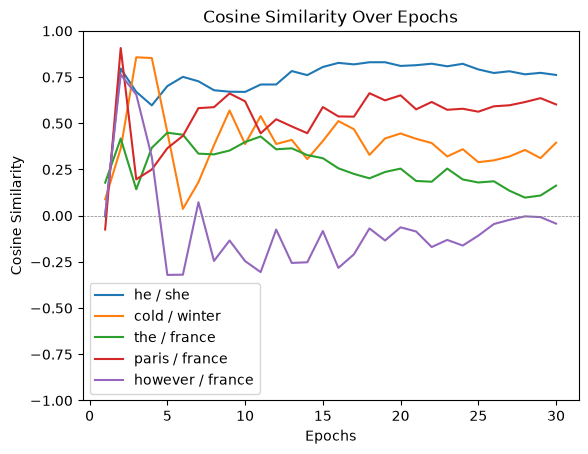

In [14]:
for (word1, word2), sim_values in similarities.items():
    plt.plot(range(1, len(sim_values) + 1), sim_values, label=f"{word1} / {word2}")
plt.xlabel("Epochs")
plt.ylabel("Cosine Similarity")
plt.title("Cosine Similarity Over Epochs")
plt.ylim(-1, 1)
plt.legend()
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.show()

## 7. Adding data

Want to add data to the training set? Easy: just append more text to `words`.

Here we add short descriptions of the words we are monitoring (*he*, *she*, *paris*, *france*, *however*, …), which put them in typical contexts.
Since `WordDataset` reads the global variable `words`, the dataset (and its length) is updated automatically. If the new text contains words absent from `stoi`, re-run the cell building `stoi` (they will be mapped to `UNK`); then re-run the training and compare the similarities.

> Note: these few hundred words are tiny compared to the 17 million words of `text8`, and each example is drawn at random positions: it is the repetition of the added text that gives it some weight.

In [15]:
words = words + """
he is a pronoun used to refer to a male person
it replaces the name of a man or boy in a sentence
for example john is happy can become he is happy
the word he is used when the person is the subject of a sentence
its corresponding object pronoun is him and its possessive form is his
he went to the store to buy some food
the teacher said he had finished his homework
when peter arrived he greeted everyone
a father said he would pick up his children
he and she are common personal pronouns in english

she is a pronoun used to refer to a female person
it replaces the name of a woman or girl in a sentence
for example mary is studying can become she is studying
the word she is used when the person is the subject of a sentence
its corresponding object pronoun is her which can also express possession
she went to the store to buy some food
the teacher said she had finished her homework
when mary arrived she greeted everyone
a mother said she would pick up her children
she and he are common personal pronouns in english

a man is an adult male human being
the word distinguishes adult males from boys who are younger
men live and work in every society around the world
the plural form of man is men
in older expressions the word man can also refer to humanity in general
a man can be a father a brother a husband or a son
the man walked down the street carrying a heavy bag
a young boy grows into a man as he becomes an adult
the man and the woman worked together on the project
many men enjoy sports music science and other activities

a woman is an adult female human being
the word distinguishes adult females from girls who are younger
women participate in every aspect of society including science politics and education
the plural form of woman is women
the word woman is often used alongside man when discussing gender
a woman can be a mother a sister a wife or a daughter
the woman walked down the street carrying a heavy bag
a young girl grows into a woman as she becomes an adult
the woman and the man worked together on the project
many women enjoy sports music science and other activities

snow is a form of precipitation consisting of small ice crystals
it forms in clouds when water vapor freezes at sufficiently low temperatures
snowflakes fall from the sky and can accumulate on the ground
snow is common during winter in regions with cold climates
the word snow can also be used as a verb to describe snow falling
snow is usually white and covers mountains forests and roads
children often enjoy playing in the snow during winter
heavy snow can make driving difficult and dangerous
snow melts into water when the temperature becomes warm enough
cold weather and freezing temperatures often bring snow

cold describes a temperature that is relatively low
something feels cold when it has less heat than its surroundings or our bodies
cold weather is common during winter in many parts of the world
the word cold can also describe an illness that causes coughing sneezing and a runny nose
the opposite of cold when describing temperature is hot
ice and snow are associated with cold temperatures
people wear warm clothes when the weather is cold
a cold winter morning can bring frost and snow
cold water feels refreshing during a hot summer day
extremely cold temperatures can freeze lakes and rivers

a car is a motor vehicle designed primarily to transport people
most cars have four wheels and are powered by an engine or an electric motor
cars are commonly used for commuting traveling and everyday transportation
different types of cars include sedans sports cars and electric vehicles
cars travel on roads and are generally controlled by drivers
a car allows people to travel long distances quickly
the driver parked the car outside the house
modern cars often include advanced safety systems
electric cars use batteries instead of gasoline engines
many families own a car to travel to work or school

a cat is a small carnivorous mammal belonging to the feline family
domestic cats are commonly kept as pets in households around the world
cats have sharp claws sensitive whiskers and excellent night vision
they are known for their agility independence and hunting abilities
cats communicate through sounds such as meowing purring and hissing
a cat often sleeps for many hours during the day
cats enjoy playing with toys and chasing small objects
a cat has soft fur four legs and a long tail
many people keep a cat as a friendly companion
cats are closely related to larger animals such as lions and tigers

paris is the capital and largest city of france
it is located in northern france along the seine river
paris is famous for landmarks such as the eiffel tower and the louvre museum
the city is an important international center for art fashion culture and tourism
paris has played a major role in french and european history
millions of tourists visit paris every year
paris is known for its museums restaurants and beautiful architecture
the french government has many important institutions in paris
paris is one of the most famous cities in europe
the capital of france is paris and its inhabitants are called parisians

france is a country located primarily in western europe
its capital city is paris which is also its largest city
france is known for its history culture cuisine and architectural heritage
the official language of france is french
france is a member of the european union and shares borders with several european countries
france has many famous cities including paris lyon and marseille
the people of france are commonly called french
france is famous for its wine cheese bread and cuisine
the eiffel tower in paris is one of the most famous landmarks in france
france has mountains beaches forests and beautiful countryside

the is a definite article used in the english language
it refers to a particular person object place or concept
for example the car identifies a specific car rather than any car
the word the can appear before both singular and plural nouns
unlike the indefinite articles a and an it generally indicates something identifiable from context
the is one of the most frequently used words in english
the article the is commonly placed before a noun
we say the sun because there is one sun in our solar system
the word the helps identify something specific in a conversation
english speakers use the in both spoken and written language

french is a romance language that developed from latin
it is the official language of france and is spoken in many other countries
the word french can also describe people culture or objects associated with france
french is spoken in parts of europe africa north america and other regions
the french language shares many grammatical and vocabulary features with other romance languages
people from france are often called french
french cuisine is famous for its bread cheese and pastries
paris is the capital of france where most people speak french
french culture includes literature art cinema and philosophy
the french language is taught in schools around the world

however is an adverb commonly used to introduce a contrast between two ideas
it often means but nevertheless or on the other hand
for example it was raining however we decided to go outside expresses a contrast
the word is frequently used in formal writing to connect opposing statements
however can also mean in whatever way or degree as in however difficult it is we will try
however is often used to introduce an unexpected or contrasting fact
the weather was cold however the children continued playing outside
the task was difficult however the students managed to finish it
however and nevertheless have similar meanings in many sentences
writers often use however to show that two ideas are in contrast

nevertheless is an adverb meaning despite that or even so
it introduces a statement that remains true despite something previously mentioned
for example the exam was difficult nevertheless she passed expresses an unexpected outcome
the word is similar in meaning to however nonetheless and still
nevertheless is particularly common in formal writing when emphasizing that something happens despite an obstacle
nevertheless is often used when something happens despite difficulties
the weather was cold nevertheless the children continued playing outside
the task was difficult nevertheless the students managed to finish it
nevertheless and however have similar meanings in many sentences
writers often use nevertheless to emphasize an unexpected result
""".split()

## 8. Going further

Look at the **nearest neighbours** of a word: compute its cosine similarity with all 10 001 embeddings and print the top 10.

In [16]:
@torch.no_grad()
def nearest_neighbours(word, k=10, embeddings=None):
    # embeddings: [vocab_size, d], one row per word
    if embeddings is None:
        embeddings = model.encoder.weight.T
    sims = F.cosine_similarity(embeddings[stoi[word]][None, :], embeddings, dim=1)
    best = sims.argsort(descending=True)[1:k + 1]  # skip the word itself
    return [(itos[j], round(sims[j].item(), 3)) for j in best]

for word in ["he", "france", "cold", "cat", "however", "three"]:
    print(f"{word:>8}: {nearest_neighbours(word)}")

      he: [('she', 0.756), ('it', 0.562), ('never', 0.526), ('accidentally', 0.525), ('ruth', 0.521), ('quickly', 0.517), ('eventually', 0.51), ('eastenders', 0.488), ('everyone', 0.478), ('confucius', 0.477)]
  france: [('spain', 0.729), ('flanders', 0.729), ('italy', 0.724), ('greece', 0.695), ('egypt', 0.69), ('england', 0.683), ('pakistan', 0.675), ('denmark', 0.661), ('germany', 0.656), ('scotland', 0.652)]
    cold: [('vietnam', 0.755), ('trojan', 0.609), ('gulf', 0.566), ('civil', 0.562), ('balkan', 0.541), ('goddesses', 0.517), ('world', 0.503), ('serbia', 0.503), ('kosovo', 0.472), ('napoleonic', 0.471)]
     cat: [('widow', 0.575), ('demonstration', 0.553), ('patient', 0.549), ('application', 0.538), ('trilogy', 0.534), ('contest', 0.533), ('pot', 0.532), ('troll', 0.532), ('knight', 0.532), ('girl', 0.524)]
 however: [('although', 0.614), ('while', 0.578), ('nevertheless', 0.541), ('whilst', 0.536), ('moreover', 0.511), ('because', 0.498), ('though', 0.498), ('that', 0.477),

Look at **analogies**: is `paris - france + italy` close to `rome`?


In [17]:
@torch.no_grad()
def analogy(a, b, c, k=5, embeddings=None):
    # a is to b what c is to ?  ->  b - a + c
    if embeddings is None:
        embeddings = model.encoder.weight.T
    target = embeddings[stoi[b]] - embeddings[stoi[a]] + embeddings[stoi[c]]
    sims = F.cosine_similarity(target[None, :], embeddings, dim=1)
    sims[[stoi[a], stoi[b], stoi[c]]] = -1  # exclude the input words
    best = sims.argsort(descending=True)[:k]
    return [(itos[j], round(sims[j].item(), 3)) for j in best]

for a, b, c in [
    ("france", "paris", "italy"),     # -> rome?
    ("france", "paris", "germany"),   # -> berlin?
    ("man", "king", "woman"),         # -> queen?
    ("he", "his", "she"),             # -> her?
    ("one", "two", "three"),          # -> four?
]:
    print(f"{a} : {b} = {c} : ?  ->  {analogy(a, b, c)}")

france : paris = italy : ?  ->  [('england', 0.602), ('rome', 0.599), ('exile', 0.591), ('honor', 0.556), ('addition', 0.547)]
france : paris = germany : ?  ->  [('rome', 0.604), ('exile', 0.588), ('arriving', 0.574), ('england', 0.569), ('palace', 0.553)]
man : king = woman : ?  ->  [('queen', 0.659), ('duke', 0.599), ('son', 0.582), ('gospel', 0.557), ('prince', 0.557)]
he : his = she : ?  ->  [('her', 0.707), ('their', 0.632), ('my', 0.6), ('your', 0.55), ('its', 0.519)]
one : two = three : ?  ->  [('hz', 0.532), ('nautical', 0.526), ('shortwave', 0.517), ('four', 0.512), ('kb', 0.486)]


Compare with the other word2vec model, **skip-gram**, which does the opposite: predict the context words from the center word.

In [18]:
class SkipGram(nn.Module):
    # Skip-gram: the opposite of CBOW, predict the context words from the center word
    def __init__(self, vocab_size, intermediate_size):
        super().__init__()
        self.vocab_size = vocab_size
        self.encoder = torch.nn.Linear(vocab_size, intermediate_size, bias=False)
        self.decoder = torch.nn.Linear(intermediate_size, vocab_size)

    def forward(self, center):
        x_tensor = torch.zeros([len(center), self.vocab_size], dtype=torch.float32)
        for i in range(len(center)):
            x_tensor[i][center[i]] = 1.0  # one-hot: a single word as input
        # one distribution over the vocabulary, shared by the 4 context positions
        return self.decoder(self.encoder(x_tensor))

# same dataset as before, with x and y swapped: x = center word, y = the 4 context words
sg_loader = DataLoader(dataset, batch_size=256)
sg_model = SkipGram(vocab_size, 100)
sg_optimizer = torch.optim.Adam(sg_model.parameters(), lr=0.003)

for epoch in range(10):
    total_loss: float = 0.0
    for context, center in sg_loader:
        y_hat = sg_model(center)  # [batch, vocab_size]
        # the same prediction must explain each of the 4 context words
        loss = F.cross_entropy(y_hat.repeat_interleave(4, dim=0), context.flatten())
        loss.backward()
        sg_optimizer.step()
        sg_optimizer.zero_grad()
        total_loss += loss.item()
    print(f"Epoch {epoch}: loss = {total_loss}")

sg_embeddings = sg_model.encoder.weight.detach().T
for word in ["he", "france", "cold"]:
    print(f"{word:>8} (CBOW)     : {nearest_neighbours(word)}")
    print(f"{word:>8} (skip-gram): {nearest_neighbours(word, embeddings=sg_embeddings)}")
print(analogy("france", "paris", "italy", embeddings=sg_embeddings))

Epoch 0: loss = 1036.7623014450073
Epoch 1: loss = 879.8002390861511
Epoch 2: loss = 852.7507648468018
Epoch 3: loss = 841.3576421737671
Epoch 4: loss = 835.5105242729187
Epoch 5: loss = 830.3963613510132
Epoch 6: loss = 827.0936331748962
Epoch 7: loss = 826.8059554100037
Epoch 8: loss = 822.9272618293762
Epoch 9: loss = 821.6682295799255
      he (CBOW)     : [('she', 0.756), ('it', 0.562), ('never', 0.526), ('accidentally', 0.525), ('ruth', 0.521), ('quickly', 0.517), ('eventually', 0.51), ('eastenders', 0.488), ('everyone', 0.478), ('confucius', 0.477)]
      he (skip-gram): [('she', 0.858), ('it', 0.711), ('later', 0.697), ('already', 0.693), ('killed', 0.688), ('never', 0.665), ('introduced', 0.656), ('soon', 0.655), ('discovered', 0.655), ('released', 0.648)]
  france (CBOW)     : [('spain', 0.729), ('flanders', 0.729), ('italy', 0.724), ('greece', 0.695), ('egypt', 0.69), ('england', 0.683), ('pakistan', 0.675), ('denmark', 0.661), ('germany', 0.656), ('scotland', 0.652)]
  fran